# Mantenimiento predictivo de una maquina CNC
Data Analytics en Gestion Industrial · Maestria en Gestion Industrial · Universidad de Ibague

## Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gdown

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, silhouette_score)

import warnings; warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

# Fase 1 — Contexto y selección del dataset

**Sector:** manufactura, mecanizado CNC. Dataset tomado del catálogo awesome-industrial-datasets.

**Problema industrial:** una fresadora CNC falla por desgaste de la herramienta, mala disipación de calor, potencia fuera de rango o sobreesfuerzo. Cada falla es una parada no programada que detiene la producción, puede dañar la pieza en proceso y frena las operaciones que dependen de la máquina (cuello de botella). Hoy el mantenimiento es correctivo. Se busca saber en qué condiciones falla la máquina y anticipar la falla.

**Ficha técnica**

| Campo | Detalle |
|---|---|
| Dataset | AI4I 2020 Predictive Maintenance Dataset |
| Origen | UCI Machine Learning Repository (id 601), S. Matzka, 2020 |
| Tipo | Sintético, refleja datos reales de mantenimiento predictivo |
| Formato y tamaño | CSV, 10.000 filas × 14 columnas |
| Variables | tipo de producto (L/M/H), temperatura del aire y del proceso (K), velocidad (rpm), torque (Nm), desgaste de la herramienta (min), falla (0/1) y 5 modos de falla |
| Última actualización | 2020 |
| Licencia | CC BY 4.0 |

**Valor del dato abierto:** los registros de fallas de una planta casi nunca son públicos. Este dataset permite construir y validar el método completo sin restricciones y luego aplicarlo a los datos reales de una planta. 

# Fase 2 — ETL

## 2.1 Ingesta

In [2]:
# Descarga del CSV desde Google Drive
url = "https://drive.google.com/uc?export=download&id=1RiKaXxOGyOaiK1XOYLrQBltDmDY4YYN1"
gdown.download(url, "datast.cvs", quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1RiKaXxOGyOaiK1XOYLrQBltDmDY4YYN1
To: c:\Users\juans\Desktop\mgi_dataanalitica-main\Proyecto\datast.cvs
100%|██████████| 522k/522k [00:00<00:00, 3.53MB/s]


'datast.cvs'

In [3]:
csv = pd.read_csv("datast.cvs")
print(csv.shape)
csv.head()
# 10000 operaciones en 14 columnas: ID, producto, 5 variables de proceso, existe falla o no y 5 modos de falla

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
# Diccionario de datos ANTES de limpiar
dic_antes = pd.DataFrame({"tipo": csv.dtypes.astype(str), # identificar tipo de variable - string numerica boleana
                          "nulos": csv.isna().sum(),  # posibles datos nulos 
                          "unicos": csv.nunique(), # cantidad de datos unicos 
                          "min": csv.min(numeric_only=True),  # maximo
                          "max": csv.max(numeric_only=True)})  # minimo
dic_antes
# Nombres en ingles con unidades; Type y Product ID como texto; dado que los datos provienen de un sistema computarizado cnc no existen datos nulos

,tipo,nulos,unicos,min,max
Air temperature [K],float64,0,93,295.3,304.5
HDF,int64,0,2,0.0,1.0
Machine failure,int64,0,2,0.0,1.0
OSF,int64,0,2,0.0,1.0
PWF,int64,0,2,0.0,1.0
Process temperature [K],float64,0,82,305.7,313.8
Product ID,str,0,10000,NaN,NaN
RNF,int64,0,2,0.0,1.0
Rotational speed [rpm],int64,0,941,1168.0,2886.0
TWF,int64,0,2,0.0,1.0


## 2.2 Limpieza

In [5]:
# Estandarizacion nombres en español y tipos de dato
df = csv.rename(columns={
    "UDI": "id", "Product ID": "id_producto", "Type": "tipo",
    "Air temperature [K]": "temp_aire", "Process temperature [K]": "temp_proceso",
    "Rotational speed [rpm]": "velocidad", "Torque [Nm]": "torque",
    "Tool wear [min]": "desgaste", "Machine failure": "falla",
})
num = ["temp_aire", "temp_proceso", "velocidad", "torque", "desgaste"]
modos = ["TWF", "HDF", "PWF", "OSF", "RNF"]
df["tipo"] = df["tipo"].astype("category") # asignar tipo como categoria (M L H) segun categoria de calidad
df[num] = df[num].astype(float) # asignar variables como columnas numericas

In [6]:
# Duplicados, nulos e inconsistencias entre la falla y los modos de falla
duplicados = df.duplicated().sum() # sumatoria de filas duplicadas 
nulos = df.isna().sum().sum() # sumatoria de la sumatoria de nulos por columna
falla_sin_modo = (df["falla"] == 1) & (df[modos].sum(axis=1) == 0) # datos que presentan falla pero las variables modo de falla no tienen valor
modo_sin_falla = (df["falla"] == 0) & (df[modos].sum(axis=1) > 0) # datos que presentan modo de falla pero no estan marcados como falla final
df = df[~(falla_sin_modo | modo_sin_falla)].copy() # falla sin modo O modo fin falla
print(duplicados) # no hay filas duplicadas 
print(nulos) # no hay datos NaN
print("Filas después de limpiar:", len(df)) # Se eliminan 27 filas con la etiqueta de falla inconsistente 

0
0
Filas después de limpiar: 9973


In [7]:
# Outliers con la regla IQR o z-score
# IQR
outliers = {}
for c in num: # num son las variables que tienen datos numericos 
    q1, q3 = df[c].quantile([0.25, 0.75]) # calculamos los cuartiles superiores e inferiores para q4
    fuera = ~df[c].between(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)) # ecuacion de aceptaion segun la regla IQR (negada para quedarse con los datos rechazados)
    outliers[c] = fuera.sum() # se hace una sumatoria en el diccionario outliners por columna 
    print(f"{c}: {fuera.sum()} outliers | tasa de falla en ellos {df.loc[fuera, 'falla'].mean() * 100:.1f} %")
# Solo hay outliers en velocidad y torque
# Sin embargo lo mas probable es que en estos outliners presenten en una falla y sean razones de falla, por ende se conservan

temp_aire: 0 outliers | tasa de falla en ellos nan %
temp_proceso: 0 outliers | tasa de falla en ellos nan %
velocidad: 418 outliers | tasa de falla en ellos 8.4 %
torque: 70 outliers | tasa de falla en ellos 88.6 %
desgaste: 0 outliers | tasa de falla en ellos nan %


In [8]:
# Reporte de calidad
pd.DataFrame({
    "Revisión": ["Duplicados", "Nulos", "Falla sin modo de falla", "Modo de falla sin falla", "Outliers velocidad", "Outliers torque"],
    "Encontrados": [duplicados, nulos, falla_sin_modo.sum(), modo_sin_falla.sum(), outliers["velocidad"], outliers["torque"]],
    "Decisión": ["Nada que corregir", "Nada que corregir", "Eliminados", "Eliminados", "Se conservan", "Se conservan"],
})

,Revisión,Encontrados,Decisión
0,Duplicados,0,Nada que corregir
1,Nulos,0,Nada que corregir
2,Falla sin modo de falla,9,Eliminados
3,Modo de falla sin falla,18,Eliminados
4,Outliers velocidad,418,Se conservan
5,Outliers torque,70,Se conservan


## 2.3 Transformación: variables derivadas y KPIs

In [9]:
df["delta_temp"] = df["temp_proceso"] - df["temp_aire"]             # La termperatura ambiental limita la apacidad de disipar el calor de la operacion(K)
df["potencia"] = df["torque"] * df["velocidad"] * 2 * np.pi / 60    # potencia final en el husillo (W)
df["esfuerzo"] = df["torque"] * df["desgaste"]                      # carga acumulada en la herramienta (min·Nm)

df["rango_desgaste"] = pd.cut(df["desgaste"], [-1, 50, 100, 150, 200, 260],
                              labels=["0-50", "51-100", "101-150", "151-200", ">200"])  # Compactar el desgaste en grupos de tiempo

df["tipo_falla"] = "Sin falla" # crear columna tipo falla y llenarla "sin falla"
for m, nombre in [("RNF", "Aleatoria"), ("OSF", "Sobreesfuerzo"), ("PWF", "Potencia"),
                  ("HDF", "Disipación de calor"), ("TWF", "Desgaste herramienta")]:   # Recorre las columnas de tipo error y llena tipo falla con el string correspondiente
    df.loc[df[m] == 1, "tipo_falla"] = nombre  # se crea una columna que sintetiza las 5 de modo de falla

kpis = pd.Series({ # key performance indicators - por la naturaleza de los datos no se puede usar indiacores como tiempo de reparacion o disponibilidad
    "Ciclos": len(df), # operaciones totales
    "Fallas": df["falla"].sum(), # operaciones donde hay fallas 
    "Tasa de falla (%)": round(df["falla"].mean() * 100, 2), # tasa de fallas 
    "Ciclos entre fallas (MTBF)": round(len(df) / df["falla"].sum(), 1), # cantidad promedio de ciclos entre fallas 
})
kpis
# 330 fallas la máquina tiene una parada no programada cada 30 ciclos en promedio

Ciclos                        9973.00
Fallas                         330.00
Tasa de falla (%)                3.31
Ciclos entre fallas (MTBF)      30.20
dtype: float64

In [10]:
# KPIs por tipo de producto
kpi_tipo = df.groupby("tipo", observed=True)["falla"].agg(ciclos="size", fallas="sum", tasa_falla="mean")
kpi_tipo["tasa_falla"] = (kpi_tipo["tasa_falla"] * 100).round(2)
kpi_tipo
# Los productos L fallan casi el doble 3,9 % que los H 2,0 %

,ciclos,fallas,tasa_falla
tipo,,,
H,998,20,2.00
L,5984,231,3.86
M,2991,79,2.64


In [11]:
# Diccionario de datos DESPUÉS de limpiar
pd.DataFrame({"tipo": df.dtypes.astype(str), "nulos": df.isna().sum(), "unicos": df.nunique()})
# 9973 filas, columnas en español, tipos corregidos y 5 variables nuevas

,tipo,nulos,unicos
id,int64,0,9973
id_producto,str,0,9973
tipo,category,0,3
temp_aire,float64,0,93
temp_proceso,float64,0,82
velocidad,float64,0,941
torque,float64,0,577
desgaste,float64,0,246
falla,int64,0,2
TWF,int64,0,2


## 2.4 Modelado de datos: Data Warehouse local

In [12]:
# Una hoja por nivel de informacion 
tabla_desgaste = (df.pivot_table(index="rango_desgaste", columns="tipo", values="falla",aggfunc="mean", observed=True) * 100).round(2) # tabla de fallas por tiempo de desgaste y tipo

with pd.ExcelWriter("ai4i_datawarehouse.xlsx") as w:              # exporar en diferentes ojas de excel
    df.to_excel(w, sheet_name="Transaccional", index=False)       # cada ciclo limpio con las variables nuevas
    kpi_tipo.to_excel(w, sheet_name="Operativa")                  # KPIs por tipo de producto
    tabla_desgaste.to_excel(w, sheet_name="Analitica")            # falla por desgaste y tipo
    kpis.to_frame("valor").to_excel(w, sheet_name="Estrategica")  # KPIs generales 
print("Data Warehouse guardado en ai4i_datawarehouse.xlsx")

Data Warehouse guardado en ai4i_datawarehouse.xlsx


# Fase 3 — EDA

## 3.1 Estadística descriptiva

In [13]:
vars_proceso = num + ["delta_temp", "potencia", "esfuerzo"] # agregar las nuevas variables a la lista de variables numericas
df[vars_proceso].describe().T.round(2) # generar tabla de medidas descriptivas de las variables numericas, con 2 decimales
# temp_proceso es unos 10 K mayor que temp_aire 
# velocidad ronda 1.500 rpm y torque 40 Nm
# El desgaste va de 0 a 253 min porque la herramienta se cambia periódicamente

,count,mean,std,min,25%,50%,75%,max
temp_aire,9973.0,300.00,2.00,295.30,298.30,300.10,301.50,304.50
temp_proceso,9973.0,310.00,1.48,305.70,308.80,310.10,311.10,313.80
velocidad,9973.0,1538.89,179.41,1168.00,1423.00,1503.00,1612.00,2886.00
torque,9973.0,39.98,9.97,3.80,33.20,40.10,46.70,76.60
desgaste,9973.0,107.92,63.65,0.00,53.00,108.00,162.00,253.00
delta_temp,9973.0,10.00,1.00,7.60,9.30,9.80,11.00,12.10
potencia,9973.0,6278.87,1067.02,1148.44,5561.77,6269.17,7001.46,10469.92
esfuerzo,9973.0,4312.96,2826.17,0.00,1963.70,4006.80,6276.40,16497.00


In [14]:
df.groupby("falla")[vars_proceso].mean().T.round(1)
# cuanto hay falla se presenta: mas torque (54 vs 40 Nm), menos velocidad (1364 vs 1507 rpm) y más desgaste (167 vs 107 min)

falla,0,1
temp_aire,300.0,300.9
temp_proceso,310.0,310.3
velocidad,1540.4,1496.2
torque,39.6,50.4
desgaste,106.7,144.5
delta_temp,10.0,9.4
potencia,6243.7,7305.4
esfuerzo,4212.2,7257.4


## 3.2 Visualizaciones

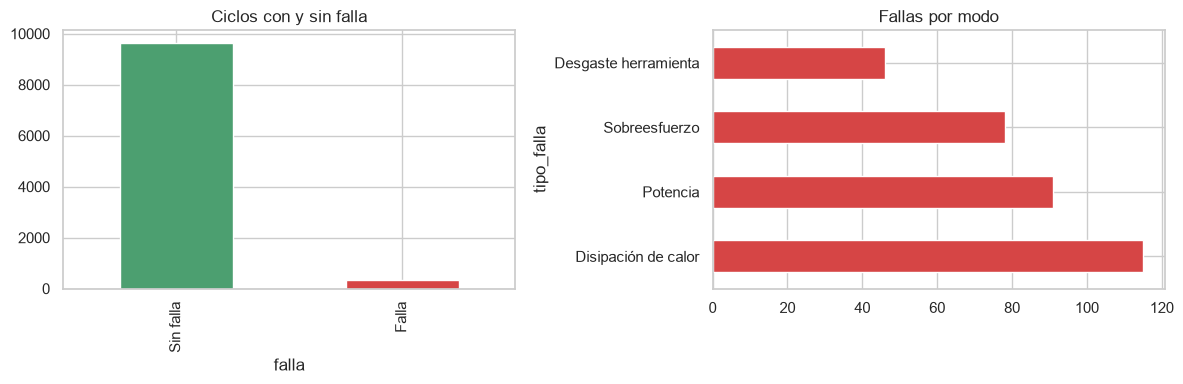

In [15]:
fallas = df[df["falla"] == 1]
sin_falla = df[df["falla"] == 0]

# Gráfica 1: balance de clases y fallas por modo
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["falla"].map({0: "Sin falla", 1: "Falla"}).value_counts().plot.bar(ax=ax[0], color=["#4C9F70", "#D64545"])
ax[0].set_title("Ciclos con y sin falla")
fallas["tipo_falla"].value_counts().plot.barh(ax=ax[1], color="#D64545")
ax[1].set_title("Fallas por modo")
plt.tight_layout(); plt.show()
# Solo el 3,3 % son fallas
# Los modos más comunes son disipación de calor (115) y potencia (91)

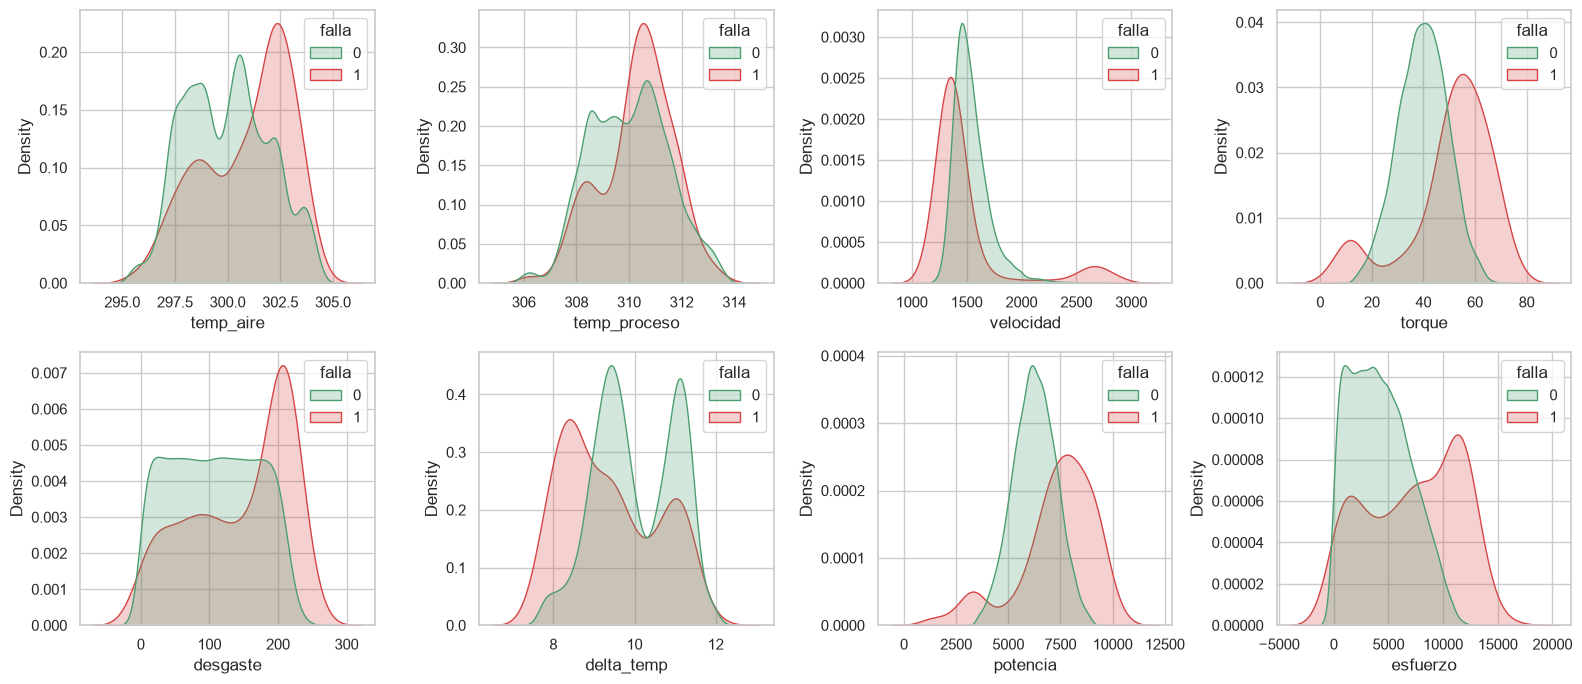

In [16]:
# Gráfica 2: distribución de cada variable con y sin falla
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), vars_proceso):
    sns.kdeplot(data=df, x=c, hue="falla", common_norm=False, fill=True, ax=ax, palette=["#4C9F70", "#D64545"])
plt.tight_layout(); plt.show()
# La velocidad tiende a ser menor cuando se presenta una falla
# El torque tiende a ser mayor cuando se presenta una falla
# Es mas comun que se presente una falla cuando el desgaste es cercano a 200
# El delta de temperatura tiende a ser menor cuando se presenta una falla
# A mayor esfuerzo y mayor potencia se presentan mas fallas

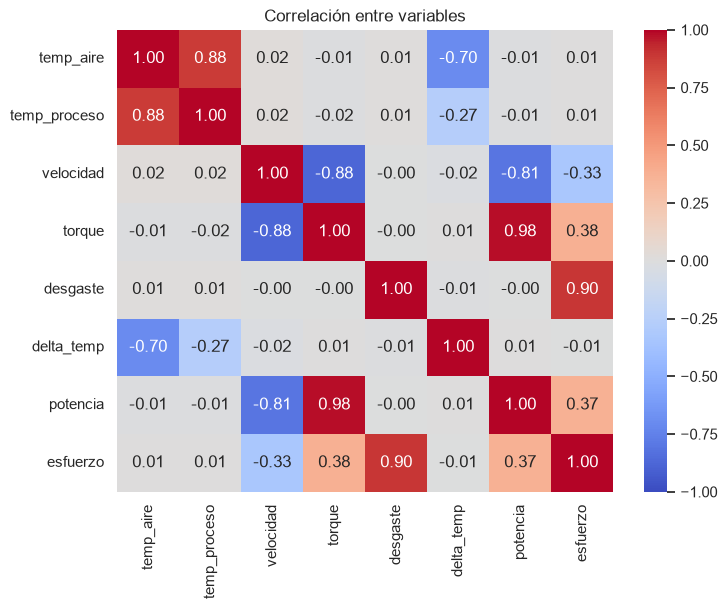

In [17]:
# Gráfica 3: correlaciones
plt.figure(figsize=(8, 6))
sns.heatmap(df[vars_proceso].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables"); plt.show()
# en este grafico se pueden evidenciar la correlacion que tienen las variables
# es decir el como estas describen a la otra, naturalmente variables relacionadas fisicamente
# velocidad y torque: -0.88  - la potencia de trabajo es casi constante, se balancea inversamente el torque y la velocidad
# potencia y torque: 0.98  - la potencia depende del torque, no es una interpretacion relevante
# temp_aire y temp_proceso: 0.88  - el proceso se calienta con el ambiente, este libera calor o lo toma del ambiente
# esfuerzo y desgaste: 0.90 - el esfuerzo depende del desgaste, no es una interpretacion relevante

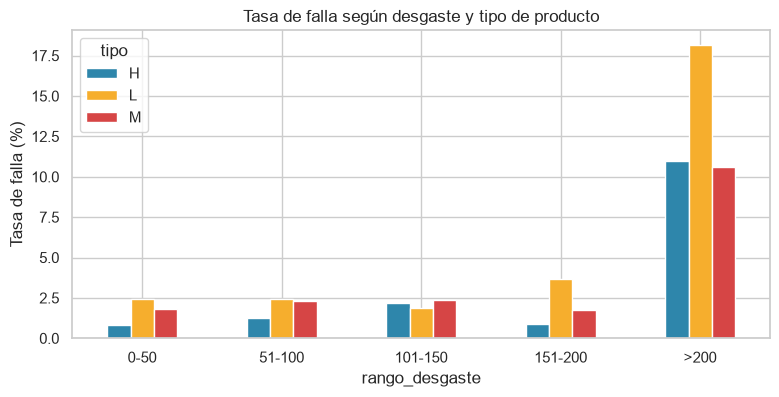

In [18]:
# Gráfica 4: KPI de tasa de falla por desgaste y tipo de producto
tabla_desgaste.plot.bar(figsize=(9, 4), color=["#2E86AB", "#F6AE2D", "#D64545"])
plt.ylabel("Tasa de falla (%)"); plt.title("Tasa de falla según desgaste y tipo de producto"); plt.xticks(rotation=0)
plt.show()
# Hasta 200 min la tasa de falla es baja (1-4 %); pasando 200 min se dispara (18 % en L, 11 % en M y H)
# Se deberia cambiar la herramienta antes de los 200 minutos

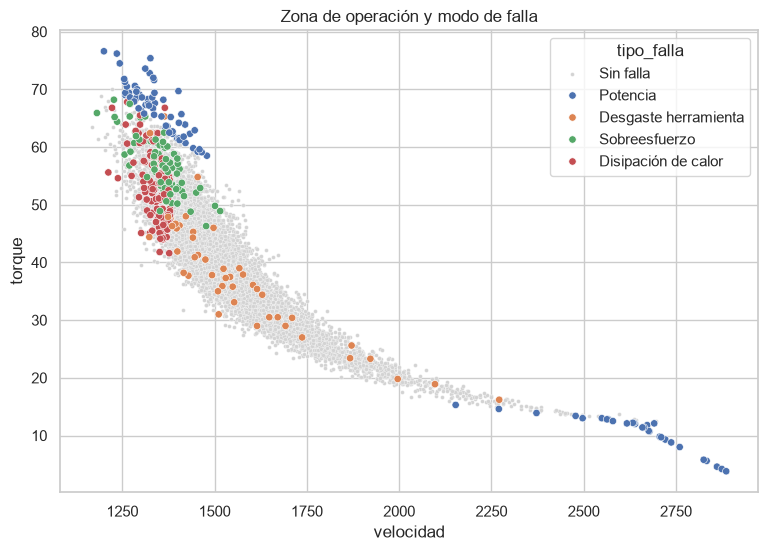

In [19]:
# Gráfica 5: zona de operación por modo de falla
plt.figure(figsize=(9, 6))
sns.scatterplot(data=sin_falla, x="velocidad", y="torque", color="lightgray", s=8, label="Sin falla")
sns.scatterplot(data=fallas, x="velocidad", y="torque", hue="tipo_falla", s=28)
plt.title("Zona de operación y modo de falla"); plt.show()
# En funcion de la potencia las fallas se presentan en los extremos de la curva 
# cola inferior - bajo torque velocidad alta fallos por potencia
# cola superior - alto torque a baja velocidad (mayor densidad) fallos por desgaste, sobreesfuerzo, disipacion
# El centro de la curva es una zona segura de operación

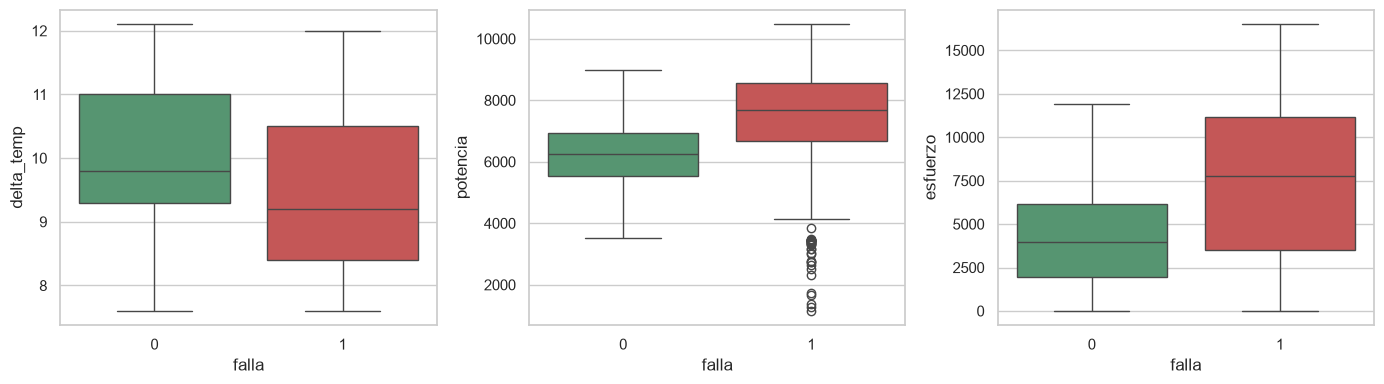

In [20]:
# Gráfica 6: variables derivadas con y sin falla
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, ["delta_temp", "potencia", "esfuerzo"]):
    sns.boxplot(data=df, x="falla", y=c, ax=ax, hue="falla", palette=["#4C9F70", "#D64545"], legend=False)
plt.tight_layout(); plt.show()
# con un delta de temperatura menor el equipo no puede dicipar el calor
# a mayor potencia mas posibilidad de error, principalmente al incrementar el torque 
# (es posible que la potencia no deba de ser linealmente la misma y a pesar de tener mas torque no se deba disminuir la velocidad)
# a mayor esfuerzo mas posibiliad de quebrar la herramienta

## 3.3 Hipótesis para la Fase 4

| Hipótesis | Técnica |
|---|---|
| H1. Hay regímenes de operación con distinto riesgo de falla | Clustering |
| H2. Las variables de proceso permiten anticipar la falla con recall > 80 % | Clasificación |
| H3. Las variables se pueden resumir en pocas componentes | PCA |
| H4. Una proyección supervisada separa los modos de falla | LDA |

# Fase 4 — Modelado analítico

## 4.1 Clustering (K-means)

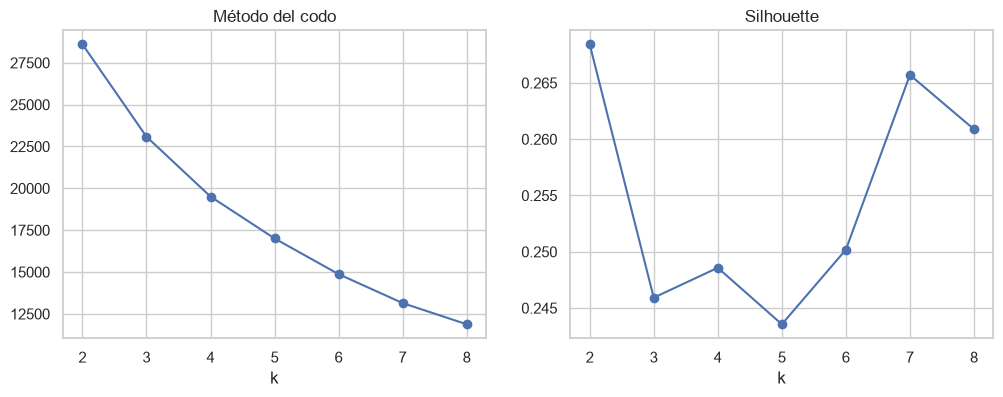

In [21]:
# Se agrupan las condiciones de operación sin usar la falla
cols_clu = ["delta_temp", "velocidad", "torque", "desgaste"] # utilizando las variables que agregamos para el analisis
X_clu = StandardScaler().fit_transform(df[cols_clu])

inercia, silueta = [], []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_clu)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(X_clu, km.labels_, sample_size=3000, random_state=RANDOM_STATE))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(2, 9), inercia, "o-"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("k")
ax[1].plot(range(2, 9), silueta, "o-"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.show()
# ploteamos por el metodo de codo y silhouette para determinar un valor optimo de k
# El codo aparece en k = 4
# la silhouette varía poco (0,24 a 0,27) naturalmente entre (1 a -1): ningún k separa mucho mejor
# Se elige k = 4 por ser el codo mas evidente

In [22]:
km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X_clu) # crea los 4 cluster, 10 iteraciones con las variables creadas
df["cluster"] = km.labels_ # agregar columna clasificador segun cluster
perfil = df.groupby("cluster")[cols_clu + ["falla"]].mean() # agrupa los datos por su cluster y calcula el promedio sin estandarizar
perfil["falla"] = perfil["falla"] * 100 # porcentaje de falla por cluster 
perfil = perfil.round(1) # 1 decimal
perfil
# Cluster 0 - operacion aparentemente normal con alto delta de temperatura - baja probabilidad de falla
# Cluster 1 - herramienta con poco desgaste pero bajo delta de temperatura - probabilidad de error modeada - fallas por calor
# Cluster 2 - herramienta gastadad con bajo delta de temperatura - probabilidad de error alta - fallos por la herramienta
# Cluster 3 - alta velocidad y bajo torque - probabilida de error baja - fallas de potencia
# H1 se cumple: el régimen de herramienta gastada falla tres veces más que la operación normal

,delta_temp,velocidad,torque,desgaste,falla
cluster,,,,,
0,11.1,1470.0,43.5,105.8,1.9
1,9.3,1471.4,43.6,51.1,3.5
2,9.3,1477.8,42.9,168.4,5.9
3,10.0,1808.7,26.1,107.4,2.0


## 4.2 Clasificación

In [23]:
X = pd.get_dummies(df[vars_proceso + ["tipo"]], columns=["tipo"], dtype=int) # se excluyen variables no operables, contextuales o que describan el error
y = df["falla"] # variable objeitvo falla 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y) # division y randomizacion de la data en 4 matrices, 80% 20%

# Estandarización: fit solo con train
scaler = StandardScaler() # formato de estandarizacion, resta la media y divide en dev estandar
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print(X_train_s.shape, X_test_s.shape, "| fallas en test:", y_test.sum()) # shape de las matrices x y la cantidad de salidas de test

(7978, 11) (1995, 11) | fallas en test: 66


In [24]:
def evaluar(modelo, Xte):
    pred = modelo.predict(Xte) # genera la prediccion usando el modelo de entrada
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()#toma los datos de test y la prediccion par generar verdaderos negativos, falsos positivos, falsos negativos, verdaderos positivos.
    return {"Accuracy": accuracy_score(y_test, pred), # proporcion correcta
            "Precisión": precision_score(y_test, pred), # Cuando da alto, que tan probable es que sea real
            "Recall": recall_score(y_test, pred),  # De las fallas reales cuales fueron detectadas
            "F1": f1_score(y_test, pred), # el modelo es bueno en recall y precision
            "ROC-AUC": roc_auc_score(y_test, modelo.predict_proba(Xte)[:, 1]), 
            "Fallas no detectadas": fn, "Falsas alarmas": fp} 

# 5 modelos, cada uno ajustado con GridSearchCV (validación cruzada de 5 particiones, optimizando F1)
modelos = {
    "Regresión logística": (LogisticRegression(max_iter=2000), {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]}), # c penalizacion de la complejidad 
    "kNN": (KNeighborsClassifier(), {"n_neighbors": [3, 5, 7, 11], "weights": ["uniform", "distance"]}), # cantidad de vecinos y si su distancia importa en el peso
    "Árbol de decisión": (DecisionTreeClassifier(random_state=RANDOM_STATE), {"max_depth": [4, 6, 8, None], "min_samples_leaf": [1, 5, 10]}), # Cuántas preguntas seguidas puede hacer y cuántos datos mínimos debe tener cada hoja
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), {"n_estimators": [100, 300], "max_depth": [None, 10]}), # Cuántos árboles y qué tan profundos.
    "AdaBoost": (AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3), random_state=RANDOM_STATE), 
                 {"n_estimators": [100, 300], "learning_rate": [0.1, 0.5, 1.0]}), #Cuántos árboles en secuencia y cuánto corrige cada uno al anterior
}
resultados, mejores = {}, {}
for nombre, (modelo, grilla) in modelos.items():
    gs = GridSearchCV(modelo, grilla, cv=5, scoring="f1", n_jobs=-1).fit(X_train_s, y_train) # prueba las combinacion posibles en los hyperparametros de los modelos, reentrena el mejor
    mejores[nombre] = gs.best_estimator_ # se guarda el modelo entrenado con la mejor combinacion   
    resultados[nombre] = evaluar(gs.best_estimator_, X_test_s) | {"F1 validación cruzada": gs.best_score_}
    print(nombre, gs.best_params_) # print la mejor combinacion

res = pd.DataFrame(resultados).T.sort_values("F1", ascending=False) # discccionario a tabla para print
res[["Fallas no detectadas", "Falsas alarmas"]] = res[["Fallas no detectadas", "Falsas alarmas"]].astype(int)
res.round(3)
# Todos superan 97 % de accuracy
# AdaBoost, Random Forest y el árbol detectan entre 55 y 58 de las 66 fallas - kNN y la logística se pierden muchas
# lo mas probable es que estos modelos lineales no puedan captar el comportamiento del sistema
# el f1 de la validacion cruzada es cercano al de test, no hay sobre cruzaje

Regresión logística {'C': 10, 'class_weight': None}
kNN {'n_neighbors': 3, 'weights': 'distance'}
Árbol de decisión {'max_depth': 6, 'min_samples_leaf': 1}
Random Forest {'max_depth': None, 'n_estimators': 300}
AdaBoost {'learning_rate': 0.5, 'n_estimators': 100}


,Accuracy,Precisión,Recall,F1,ROC-AUC,Fallas no detectadas,Falsas alarmas,F1 validación cruzada
AdaBoost,0.994,0.951,0.879,0.913,0.993,8,3,0.898
Random Forest,0.994,0.935,0.879,0.906,0.990,8,4,0.901
Árbol de decisión,0.994,0.982,0.833,0.902,0.973,11,1,0.890
kNN,0.977,0.763,0.439,0.558,0.878,37,9,0.525
Regresión logística,0.972,0.750,0.227,0.349,0.947,51,5,0.393


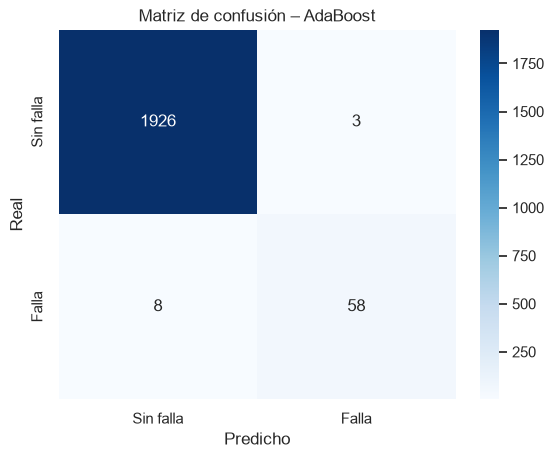

In [25]:
# Matriz de confusión del mejor modelo
mejor = res.index[0] # se toma el de mejor
cm = confusion_matrix(y_test, mejores[mejor].predict(X_test_s))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Sin falla", "Falla"], yticklabels=["Sin falla", "Falla"])
plt.title(f"Matriz de confusión – {mejor}"); plt.xlabel("Predicho"); plt.ylabel("Real"); plt.show()
# AdaBoost detecta 58 de 66 fallas 
# dio 3 falsas alarmas en 1929 ciclos normales
# Costo del error: una falla no detectada es una parada no programada (reparación, pieza perdida, línea detenida) 
# una falsa alarma es solo una inspección preventiva que se programa entre turnos. 
# por eso se toma como prioridad el recall, lo mas importante detectar las fallas reales, sin importar dar falsos positivos
# Sin modelo habría 66 paradas no programadas; con el modelo quedan 8
# H2 se cumple (recall 0,88 > 0,80)

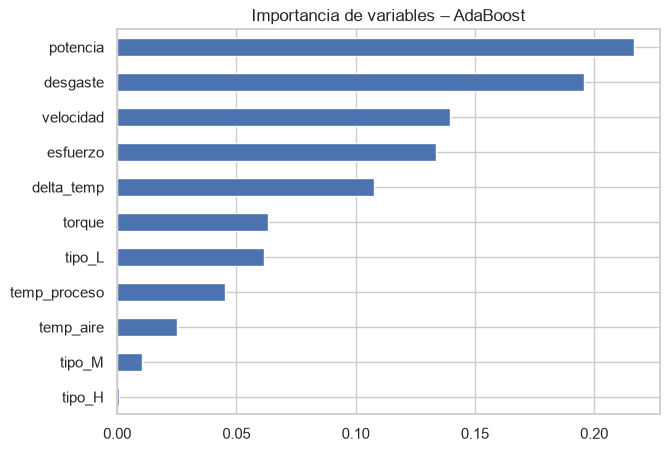

In [26]:
# Importancia de variables del mejor modelo
pd.Series(mejores[mejor].feature_importances_, index=X.columns).sort_values().plot.barh(figsize=(7, 5)) # se extrae el vector de valor del modelo en funcion de las variables
plt.title(f"Importancia de variables – {mejor}"); plt.show()
# Potencia, desgaste, velocidad, esfuerzo y delta_temp pesan más - las mismas variables que destacó el EDA

## 4.3 PCA

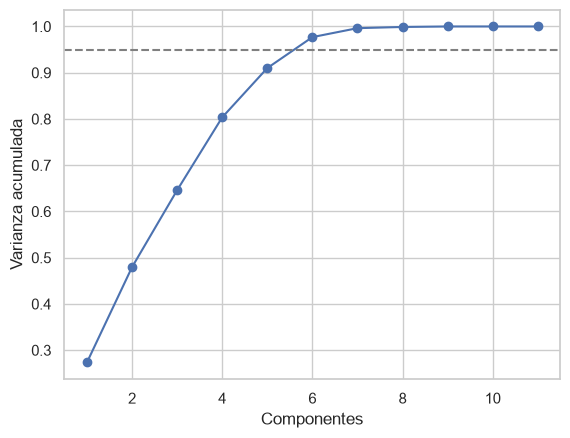

Componentes para superar el 95 %: 6 | varianza: 97.7 %


In [27]:
# Varianza explicada acumulada (datos ya estandarizados) cada componente acumula una parte de la varianza 
pca = PCA().fit(X_train_s) # calcualar la cantidad de componentes adicionables, maximo 11 - 1 por variable
acumulada = np.cumsum(pca.explained_variance_ratio_) # Proporcion a cada de varianza a cada componente acumulada
plt.plot(range(1, len(acumulada) + 1), acumulada, "o-"); plt.axhline(0.95, ls="--", color="gray")
plt.xlabel("Componentes"); plt.ylabel("Varianza acumulada"); plt.show()
n_comp = int(np.argmax(acumulada >= 0.95) + 1)
print("Componentes para superar el 95 %:", n_comp, "| varianza:", round(acumulada[n_comp - 1] * 100, 1), "%")
# Se eligen 6 componentes es el mínimo que supera el 95 % de la varianza

In [28]:
# Loadings peso de cada variable en las primeras 4 componentes
pd.DataFrame(pca.components_[:4].T, index=X.columns, columns=["PC1", "PC2", "PC3", "PC4"]).round(2)
# PC1 = carga mecánica (torque y potencia +, velocidad -) 
# PC2 = temperatura (aire y proceso +, delta_temp -)
# PC3 = tipo de producto (L vs M) 
# PC4 = desgaste de la herramienta (desgaste y esfuerzo) 
# Cada componente describe en mayor medida el peso de un conjunto de variables

,PC1,PC2,PC3,PC4
temp_aire,-0.03,0.66,-0.03,-0.05
temp_proceso,-0.03,0.56,-0.03,-0.04
velocidad,-0.51,0.00,0.05,0.19
torque,0.55,0.01,-0.05,-0.20
desgaste,0.15,0.06,0.15,0.71
delta_temp,0.02,-0.49,0.02,0.04
potencia,0.54,0.01,-0.05,-0.19
esfuerzo,0.35,0.06,0.12,0.58
tipo_H,-0.01,-0.03,-0.17,0.06
tipo_L,0.02,0.03,0.71,-0.16


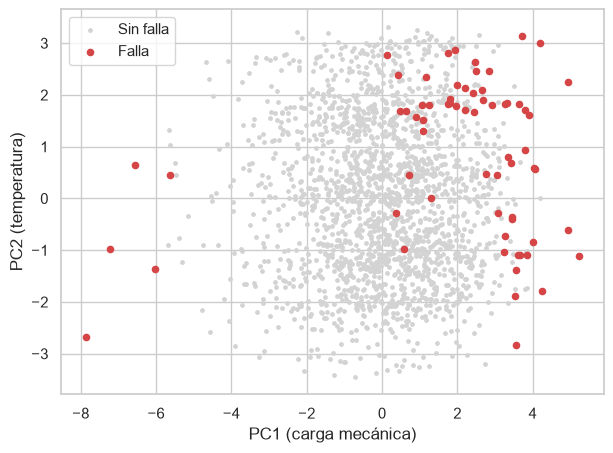

,F1 sin PCA,F1 con PCA
AdaBoost,0.913,0.580
Random Forest,0.906,0.600
Regresión logística,0.349,0.030
kNN,0.558,0.505
Árbol de decisión,0.902,0.538


In [29]:
# visualización 2D
Z = pca.transform(X_test_s) # se transforma los datos de prueba, al nuevo sistema de componentes
plt.figure(figsize=(7, 5))
plt.scatter(Z[y_test == 0, 0], Z[y_test == 0, 1], s=6, color="lightgray", label="Sin falla") 
plt.scatter(Z[y_test == 1, 0], Z[y_test == 1, 1], s=20, color="#D64545", label="Falla")
plt.xlabel("PC1 (carga mecánica)"); plt.ylabel("PC2 (temperatura)"); plt.legend(); plt.show() 
# se plotea el scatter usando los dos primeros componentes y resaltando los casos de falla
# En 2D casi todas las fallas quedan en el extremo derecho de PC1 (carga mecánica alta) y unas pocas en el izquierdo
# usando mas dimensiones los casos de falla se acumularian en un punto

# preprocesamiento antes de clasificar - se crea un clon de los modelos en sus hyperparametros previamente a ser entrenados y aplica PCA
con_pca = {n: f1_score(y_test, Pipeline([("pca", PCA(n_components=n_comp)), ("m", clone(m))]).fit(X_train_s, y_train).predict(X_test_s))
           for n, m in mejores.items()}
pd.DataFrame({"F1 sin PCA": res["F1"], "F1 con PCA": pd.Series(con_pca)}).round(3)
# Con PCA el F1 baja en todos los modelos (AdaBoost de 0,91 a 0,58): PCA mezcla los umbrales que causan la falla 
# H3 se cumple en parte: PCA resume bien las variables y sirve para visualizar, pero no para predecir

## 4.4 LDA

In [30]:
# LDA como reducción supervisada antes de clasificar comparación con y sin LDA
con_lda = {n: f1_score(y_test, Pipeline([("lda", LinearDiscriminantAnalysis()), ("m", clone(m))]).fit(X_train_s, y_train).predict(X_test_s))
           for n, m in mejores.items()} # crea un clon y transforma las 11 variables en 1 eje discriminante ajustado solo con el train

pd.DataFrame({"F1 sin LDA": res["F1"], "F1 con LDA": pd.Series(con_lda)}).round(3)
# Con dos clases LDA deja un solo eje y el F1 cae en todos (AdaBoost de 0,91 a 0,19)
# Los modelos de árboles pierden las reglas no lineales al quedar con un solo eje
# la proyeccion de la linealidad del modelo no es coherente con el comportamiento del sistema 

,F1 sin LDA,F1 con LDA
AdaBoost,0.913,0.189
Random Forest,0.906,0.246
Regresión logística,0.349,0.247
kNN,0.558,0.276
Árbol de decisión,0.902,0.289


In [31]:
# Eje discriminante: peso de cada variable
lda = LinearDiscriminantAnalysis().fit(X_train_s, y_train)
pd.Series(lda.scalings_[:, 0], index=X.columns).sort_values().round(2)
# El eje discriminante del LDA lo conforman las variables que mas peso tienen dentro del modelo
# El eje discriminante lo forman torque (+5,0), potencia (-3,2) y velocidad (+2,1): es decir la carga mecánica 

potencia       -3.17
desgaste       -0.68
delta_temp     -0.21
temp_proceso   -0.03
tipo_M         -0.03
tipo_H         -0.01
tipo_L          0.03
temp_aire       0.08
esfuerzo        1.05
velocidad       2.08
torque          5.01
dtype: float64

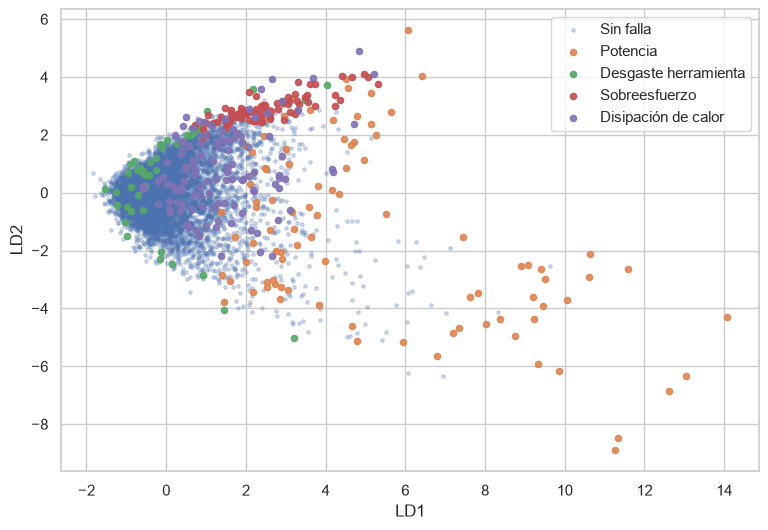

In [32]:
# LDA con los modos de falla: dos ejes discriminantes
d = df[df["tipo_falla"] != "Aleatoria"] # Quitar las fallas aleatorias dado que no se ajustan a ninguna condicion o se derivan de una causa fisica
Zl = Pipeline([("sc", StandardScaler()), ("lda", LinearDiscriminantAnalysis(n_components=2))]).fit_transform(d[vars_proceso], d["tipo_falla"]) 
# se grafican dos ejes discriminates en un plano, los dos mejores
plt.figure(figsize=(9, 6))
for c in d["tipo_falla"].unique():
    m = (d["tipo_falla"] == c).values
    plt.scatter(Zl[m, 0], Zl[m, 1], s=6 if c == "Sin falla" else 20, alpha=0.25 if c == "Sin falla" else 0.9, label=c)
plt.xlabel("LD1"); plt.ylabel("LD2"); plt.legend(); plt.show()
# LD1 separa las fallas de potencia del resto;
# LD2 separa sobreesfuerzo (arriba) de potencia (abajo)
# Las de desgaste quedan mezcladas con los ciclos normales porque dependen del tiempo de uso y el eje discriminante es la carga
# H4 se cumple en parte: LDA separa bien las causas mecánicas y sirve para interpretarlas, no para predecir

## 4.5 Comparación y elección del modelo final

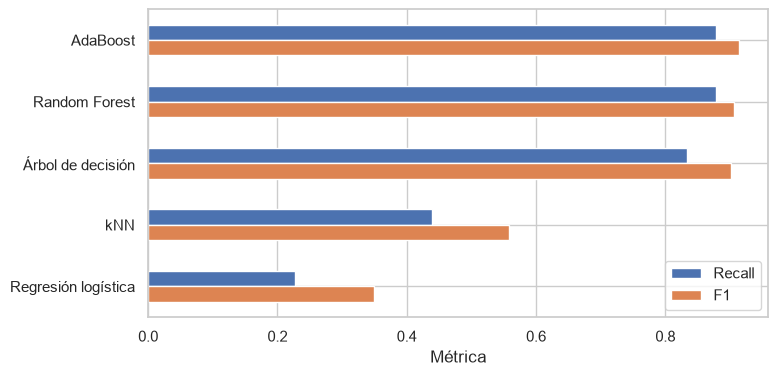

In [33]:
res[["Recall", "F1"]].plot.barh(figsize=(8, 4)); plt.gca().invert_yaxis(); plt.xlabel("Métrica"); plt.show()
# Modelo final: AdaBoost. Mejor F1 (0,91), detecta 88 % de las fallas, solo 3 falsas alarmas

# Fase 5 — Dashboard y propuesta

## 5.1 Datos para el dashboard

In [34]:
# dashboard.py lee estos archivos. Para abrirlo: streamlit run dashboard.py
import os, json
os.makedirs("dashboard_datos", exist_ok=True)
df.to_csv("dashboard_datos/datos.csv", index=False)
res.to_csv("dashboard_datos/metricas.csv")
perfil.to_csv("dashboard_datos/perfil_clusters.csv")
pd.DataFrame({"F1 sin PCA": res["F1"], "F1 con PCA": pd.Series(con_pca)}).to_csv("dashboard_datos/comparacion_pca.csv")
pd.DataFrame({"F1 sin LDA": res["F1"], "F1 con LDA": pd.Series(con_lda)}).to_csv("dashboard_datos/comparacion_lda.csv")
final = mejores[mejor]
json.dump({"modelo": mejor, "n_estimators": int(final.n_estimators), "learning_rate": float(getattr(final, "learning_rate", 1.0)),
           "max_depth": int(final.estimator.max_depth) if mejor == "AdaBoost" else None},
          open("dashboard_datos/modelo_final.json", "w"))
print(os.listdir("dashboard_datos"))

['comparacion_lda.csv', 'comparacion_pca.csv', 'datos.csv', 'metricas.csv', 'modelo_final.json', 'perfil_clusters.csv']


## 5.2 Plan de acción

| Acción | Hallazgo que la respalda | Costo | Riesgo | Seguimiento |
|---|---|---|---|---|
| Cambiar la herramienta a los 190 min | La falla se dispara después de 200 min | Bajo | Más consumo de herramientas | Fallas por desgaste y sobreesfuerzo |
| Mantenimiento preventivo guiado por el modelo | Detecta cerca de 9 de cada 10 fallas | Medio | Algunas inspecciones innecesarias | Recall y paradas no programadas por mes |
| Limitar el torque en productos L | Con esfuerzo > 11.000 la falla llega al 82 % | Bajo | Menor ritmo de producción en L | Fallas por sobreesfuerzo |
| Revisar la refrigeración si delta_temp < 8,6 K | En esa condición la falla llega al 17 % | Medio | Paradas cortas de revisión | Fallas por disipación de calor |
| Operar entre 3.500 y 9.000 W | Las fallas de potencia ocurren fuera de ese rango | Bajo | Ajustar programas de corte | Fallas por potencia |